# Chapitre 18 - Exercices 18.11 à 18.15

Ce notebook traite cinq exercices du chapitre 18 (*problèmes en grande dimension,
$p \gg N$*) :

- **18.11** : la régression logistique n'a pas d'estimateur du maximum de vraisemblance
  quand les classes sont séparables ;
- **18.12** : validation croisée de la ridge avec la réduction $X = RV^T$ calculée une
  seule fois ;
- **18.13** : régression logistique ridge à partir de la seule matrice des produits
  scalaires $K = XX^T$ (et d'un noyau quelconque) ;
- **18.14** : le 1-plus-proche-voisin pondéré par les distances, vu comme une
  analyse discriminante non paramétrique ;
- **18.15** : ACP à noyau et projection d'un nouveau point.

Les fonctions utilisées sont dans le module `esl/ch18_grande_dimension_complements.py`.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import ch18_grande_dimension_complements as g18
set_style()

## Exercice 18.11 : Classes séparables : la logistique n'a pas de maximum

**Énoncé (reformulé).** On dispose de $N$ couples $(x_i, y_i)$ avec $x_i \in \mathbb{R}$ et
$y_i \in \{0, 1\}$. On suppose les deux classes **séparées** : il existe $C > 0$ tel que,
pour tout $i$ de la classe $0$ et tout $i'$ de la classe $1$, $x_{i'} - x_i \ge C$.
On veut ajuster par maximum de vraisemblance le modèle logistique
$\operatorname{logit} \Pr(Y = 1 \mid X) = \alpha + \beta X$.
Montrer que $\hat\beta$ n'est pas défini.

### Rappels

On note $\sigma(\eta) = \dfrac{1}{1 + e^{-\eta}}$ la fonction logistique et
$\eta_i = \alpha + \beta x_i$ le prédicteur linéaire. Le modèle dit
$\Pr(Y = 1 \mid x_i) = \sigma(\eta_i)$. La log-vraisemblance s'écrit

$$
\ell(\alpha, \beta) = \sum_{i=1}^N \Big[ y_i \log \sigma(\eta_i)
  + (1 - y_i) \log\big(1 - \sigma(\eta_i)\big) \Big].
$$

Chaque terme est le logarithme d'une probabilité strictement comprise entre $0$ et $1$
(car $0 < \sigma(\eta) < 1$ pour tout réel $\eta$) : **chaque terme est strictement
négatif**, donc $\ell(\alpha, \beta) < 0$ pour tout $(\alpha, \beta) \in \mathbb{R}^2$.

### Étape 1 : la borne supérieure de $\ell$ vaut $0$

Notons $a = \max\{x_i : y_i = 0\}$ et $b = \min\{x_{i'} : y_{i'} = 1\}$. L'hypothèse de
séparation donne $b - a \ge C > 0$. Posons $c = (a + b)/2$, le milieu de « l'espace vide »
entre les deux classes. Alors

- si $y_i = 1$ : $x_i - c \ge b - c = (b - a)/2 \ge C/2$ ;
- si $y_i = 0$ : $x_i - c \le a - c = -(b - a)/2 \le -C/2$.

Choisissons $\beta = n$ et $\alpha = -nc$, de sorte que $\eta_i = n(x_i - c)$.
Quand $n \to +\infty$ :

- pour $y_i = 1$, $\eta_i \ge nC/2 \to +\infty$ donc $\log \sigma(\eta_i) \to 0$ ;
- pour $y_i = 0$, $\eta_i \le -nC/2 \to -\infty$ donc $\log(1 - \sigma(\eta_i)) \to 0$.

Par somme d'un nombre fini de termes, $\ell(-nc, n) \to 0$. Comme $\ell < 0$ partout,
on conclut que $\sup_{(\alpha, \beta)} \ell(\alpha, \beta) = 0$.

### Étape 2 : cette borne n'est jamais atteinte

Le maximum de vraisemblance serait un point $(\hat\alpha, \hat\beta)$ tel que
$\ell(\hat\alpha, \hat\beta) = \sup \ell = 0$. Or $\ell(\alpha, \beta) < 0$ en **tout**
point de $\mathbb{R}^2$ : un tel point n'existe pas. L'estimateur du maximum de
vraisemblance n'est donc pas défini.

On peut préciser ce que font les suites « maximisantes » $(\alpha_n, \beta_n)$ avec
$\ell(\alpha_n, \beta_n) \to 0$. Chaque terme (négatif) doit tendre vers $0$, donc
$\eta_{i'} \to +\infty$ pour toute observation $i'$ de la classe $1$ et
$\eta_i \to -\infty$ pour toute observation $i$ de la classe $0$. En particulier

$$
\beta_n (x_{i'} - x_i) = \eta_{i'} - \eta_i \longrightarrow +\infty ,
$$

et comme $0 < C \le x_{i'} - x_i$ est fixé, nécessairement $\beta_n \to +\infty$ :
« $\hat\beta = +\infty$ ». C'est ce qu'on entend par *$\hat\beta$ non défini*.

> **Intuition.** Quand les classes sont séparées, plus la pente est raide, plus la
> sigmoïde ressemble à une marche placée dans le trou entre les classes, et plus chaque
> probabilité ajustée se rapproche de $0$ ou de $1$ : la vraisemblance s'améliore sans fin.

### Vérification numérique

On simule deux classes séparées sur la droite réelle et on lance une montée de gradient
sur $\ell$ (fonction `logistic_gradient_ascent`). Si un maximum existait, les
coefficients se stabiliseraient.

In [2]:
rng = np.random.RandomState(0)
x0 = rng.uniform(-3, -0.5, 15)
x1 = rng.uniform(0.5, 3, 15)
x = np.r_[x0, x1][:, None]
y = np.r_[np.zeros(15), np.ones(15)]
print("écart minimal entre classes C =", round(x1.min() - x0.max(), 3))

écart minimal entre classes C = 1.141


In [3]:
iters, path, ll = g18.logistic_gradient_ascent(x, y, n_iter=30000, lr=2.0)
print("itération   beta      alpha    log-vraisemblance")
for k in np.linspace(0, len(iters) - 1, 6).astype(int):
    print("%9d  %8.3f  %8.3f  %.2e" % (iters[k], path[k, 1], path[k, 0], ll[k]))

itération   beta      alpha    log-vraisemblance
        1     1.696     0.000  -2.95e+00
       16     3.034    -0.060  -9.56e-01
      111     4.985     0.007  -2.39e-01
      642     7.313     0.059  -5.18e-02
     4389    10.179     0.107  -8.55e-03
    30000    13.219     0.168  -1.34e-03


La pente $\beta$ croît sans s'arrêter (de façon logarithmique en le nombre d'itérations)
tandis que la log-vraisemblance tend vers $0$ par valeurs négatives.

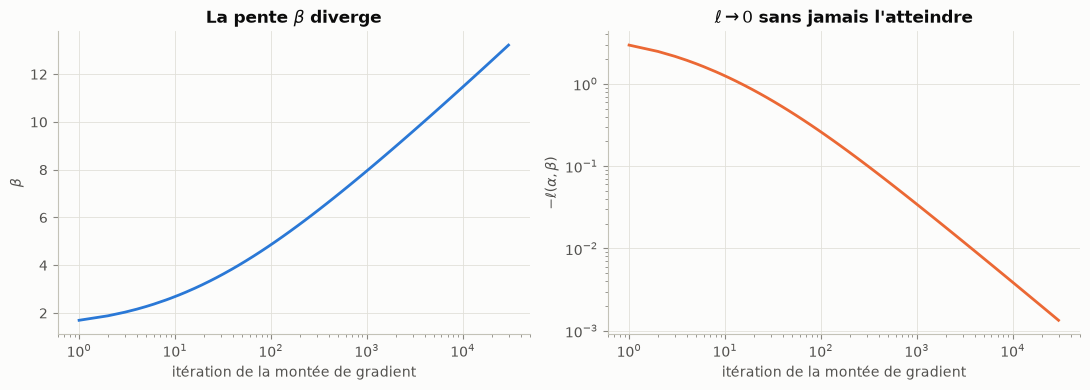

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].semilogx(iters, path[:, 1], color=BLUE)
axes[0].set_xlabel("itération de la montée de gradient")
axes[0].set_ylabel(r"$\beta$")
axes[0].set_title(r"La pente $\beta$ diverge")
axes[1].loglog(iters, -ll, color=ORANGE)
axes[1].set_xlabel("itération de la montée de gradient")
axes[1].set_ylabel(r"$-\ell(\alpha, \beta)$")
axes[1].set_title(r"$\ell \to 0$ sans jamais l'atteindre")
plt.tight_layout()
plt.show()

Visualisons les courbes ajustées $x \mapsto \sigma(\alpha + \beta x)$ à différentes
itérations : elles tendent vers une fonction en escalier.

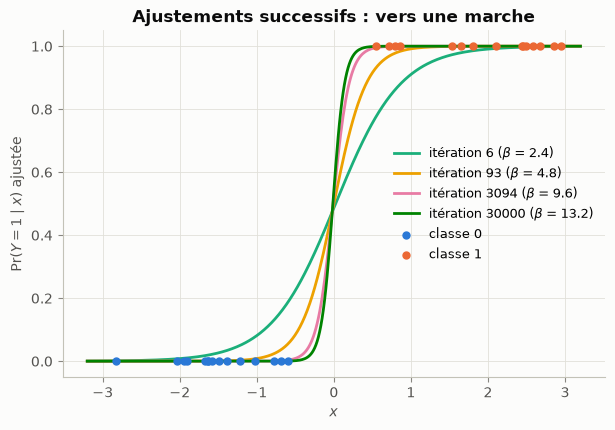

In [5]:
grid = np.linspace(-3.2, 3.2, 400)
fig, ax = plt.subplots(figsize=(7, 4.5))
for c, k in zip(COLORS[2:], [5, 20, 40, len(iters) - 1]):
    ax.plot(grid, g18.sigmoid(path[k, 0] + path[k, 1] * grid), color=c,
            label=r"itération %d ($\beta$ = %.1f)" % (iters[k], path[k, 1]))
ax.scatter(x0, np.zeros(15), color=BLUE, label="classe 0", zorder=3)
ax.scatter(x1, np.ones(15), color=ORANGE, label="classe 1", zorder=3)
ax.set_xlabel("$x$")
ax.set_ylabel(r"$\Pr(Y=1 \mid x)$ ajustée")
ax.set_title("Ajustements successifs : vers une marche")
ax.legend(loc="center right")
plt.show()

### Lien avec le chapitre : en grande dimension, tout est séparable

Quand $p \ge N - 1$, $N$ points « génériques » de $\mathbb{R}^p$ sont **toujours**
linéairement séparables, quelles que soient leurs étiquettes : le système
$\alpha + x_i^T\beta = s_i$ ($i = 1, \dots, N$) a $p + 1 \ge N$ inconnues et admet une
solution pour tout second membre, en particulier $s_i = +1$ pour la classe 1 et $-1$
pour la classe 0. L'argument précédent s'applique alors dans la direction $\beta$ trouvée :
la logistique non pénalisée n'a jamais de solution si $p \gg N$. D'où l'usage, dans tout
le chapitre, d'une **pénalité quadratique** $\lambda \|\beta\|^2$ : le critère pénalisé
tend vers $-\infty$ (en vraisemblance pénalisée) quand $\|\beta\| \to \infty$, et le
maximum existe.

In [6]:
N, p = 30, 100
X = rng.randn(N, p)
yrand = rng.randint(0, 2, N)                      # étiquettes purement aléatoires
s = 2.0 * yrand - 1
Xa = np.c_[np.ones(N), X]
w = np.linalg.lstsq(Xa, s, rcond=None)[0]         # solution exacte du système
print("marge minimale y_i * (alpha + x_i^T beta) =", np.min(s * (Xa @ w)).round(6))
for lam in [10.0, 1.0, 0.1, 0.01, 1e-3, 1e-4]:
    b0, b = g18.logistic_ridge(X, yrand, lam)
    print("lambda = %7.0e   ||beta_hat|| = %5.2f" % (lam, np.linalg.norm(b)))

marge minimale y_i * (alpha + x_i^T beta) = 1.0


lambda =   1e+01   ||beta_hat|| =  0.62


lambda =   1e+00   ||beta_hat|| =  1.63


lambda =   1e-01   ||beta_hat|| =  2.82


lambda =   1e-02   ||beta_hat|| =  4.10


lambda =   1e-03   ||beta_hat|| =  5.44


lambda =   1e-04   ||beta_hat|| =  6.81


Avec des étiquettes tirées au hasard, les données sont pourtant parfaitement séparées
(marge $= 1$), et la norme de l'estimateur logistique ridge croît sans borne quand
$\lambda \to 0$ (lentement, à peu près comme $\log(1/\lambda)$, comme la pente de la
montée de gradient ci-dessus).

> **À retenir.** Si les classes sont séparables, $\ell(\alpha, \beta) < 0$ partout mais
> $\sup \ell = 0$ : le maximum n'est pas atteint et $|\hat\beta| = \infty$. Pour $p \ge N-1$
> c'est la règle et non l'exception : il faut régulariser.

## Exercice 18.12 : Validation croisée de la ridge : réduire $X$ une seule fois

**Énoncé (reformulé).** On veut choisir le paramètre ridge $\lambda$ par validation
croisée à 10 blocs, pour un modèle linéaire quelconque à pénalité quadratique, dans une
situation $p \gg N$, en utilisant les raccourcis de calcul de la section 18.3.5.
Montrer qu'il suffit de réduire **une seule fois** la matrice $X$ ($N \times p$) en la
matrice $R$ ($N \times N$), et d'utiliser $R$ dans toutes les étapes de la validation
croisée.

### Rappels : la réduction $X = RV^T$ (éq. (18.12)–(18.13) du livre)

La décomposition en valeurs singulières (SVD) de $X$ s'écrit $X = UDV^T$, avec $U$
($N \times N$) orthogonale, $D$ diagonale ($N \times N$) et $V$ ($p \times N$) à
colonnes orthonormées : $V^TV = I_N$. On pose $R = UD$ ($N \times N$), de sorte que
$X = RV^T$. Ligne par ligne : $x_i = V r_i$, où $r_i^T$ est la $i$-ème ligne de $R$.

Le **théorème (18.16)–(18.17)** dit : pour toute perte $L$ et tout $\lambda > 0$,

$$
\min_{\beta_0, \beta \in \mathbb{R}^p} \sum_{i=1}^N L(y_i, \beta_0 + x_i^T\beta) + \lambda \beta^T\beta
\quad\text{et}\quad
\min_{\theta_0, \theta \in \mathbb{R}^N} \sum_{i=1}^N L(y_i, \theta_0 + r_i^T\theta) + \lambda \theta^T\theta
$$

ont des solutions liées par $\hat\beta_0 = \hat\theta_0$ et $\hat\beta = V\hat\theta$.

### Ce que la preuve du théorème utilise vraiment

Rappelons l'argument (c'est l'objet de l'exercice 18.5). Tout $\beta \in \mathbb{R}^p$ se
décompose en $\beta = V\theta + \beta_\perp$ avec $\theta = V^T\beta$ et
$V^T\beta_\perp = 0$ (projection orthogonale sur l'image de $V$). Alors :

1. $x_i^T\beta = r_i^T V^T V\theta + r_i^T V^T\beta_\perp = r_i^T\theta$, car $V^TV = I$
   et $V^T\beta_\perp = 0$ : **la perte ne dépend que de $\theta$** ;
2. $\beta^T\beta = \theta^T\theta + \|\beta_\perp\|^2$ (Pythagore) : la pénalité est
   minimale pour $\beta_\perp = 0$.

Donc à l'optimum $\beta_\perp = 0$, $\hat\beta = V\hat\theta$, et $\hat\theta$ résout le
problème réduit. **Point clé :** la preuve n'utilise que deux faits,
(i) chaque ligne s'écrit $x_i = Vr_i$ et (ii) $V^TV = I$. Elle n'utilise **pas** le fait
que $R$ et $V$ proviennent de la SVD *de la matrice sur laquelle on ajuste*.